Initial CALABARZON Dataset Shape: (58319, 27)

Missing Values Before Cleaning:
visibility            56
main.sea_level      5127
main.grnd_level     5127
wind.gust           8547
sys.type           24008
sys.id             24008
rain.1h            52845
dtype: int64

Duplicate rows found: 0
Imputed 'wind.gust' missing values with median: 4.47
Imputed 'main.sea_level' missing values with median: 1010.00
Imputed 'main.grnd_level' missing values with median: 1001.00
Imputed 'visibility' missing values with median: 10000.00

Missing Values After Cleaning: 0
Cleaned Dataset Shape: (58319, 18)

Target Class Distribution (Is_Rain_Storm):
Is_Rain_Storm
0    52877
1     5442
Name: count, dtype: int64
Is_Rain_Storm
0    90.67
1     9.33
Name: proportion, dtype: float64


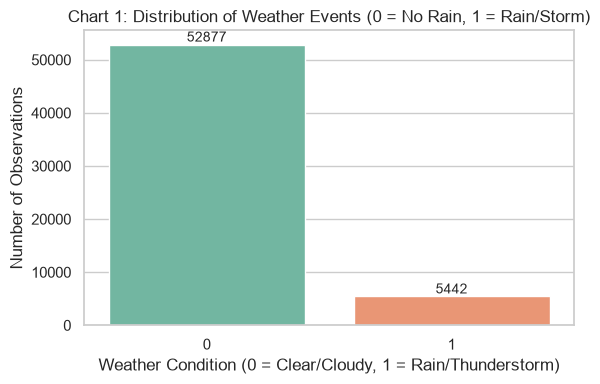

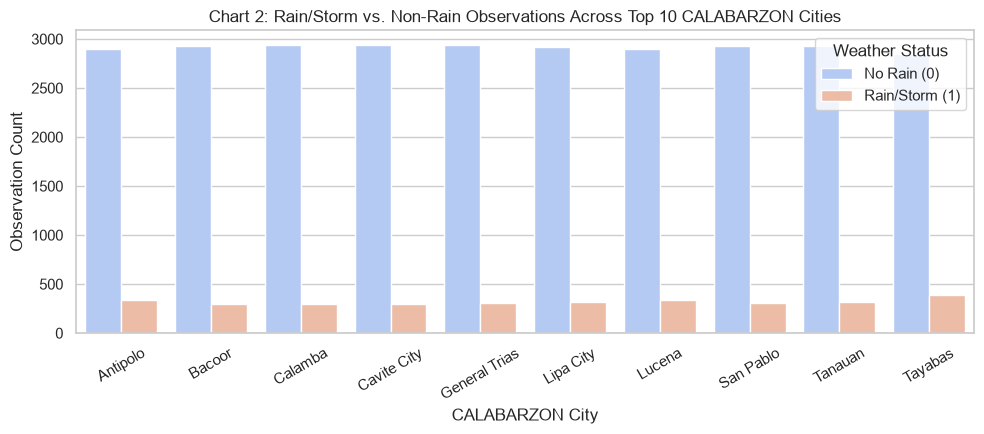

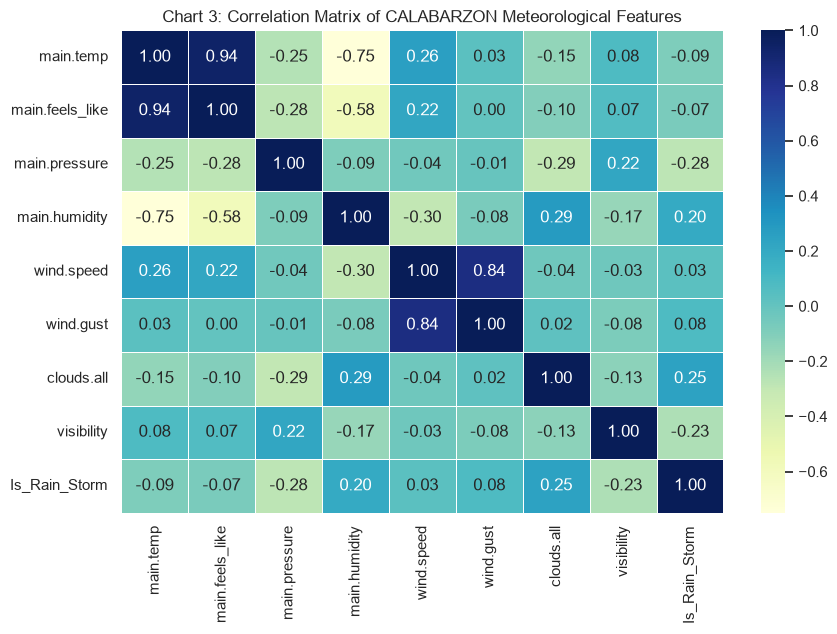

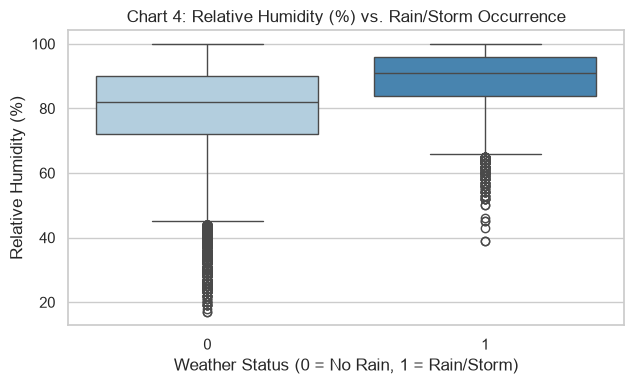

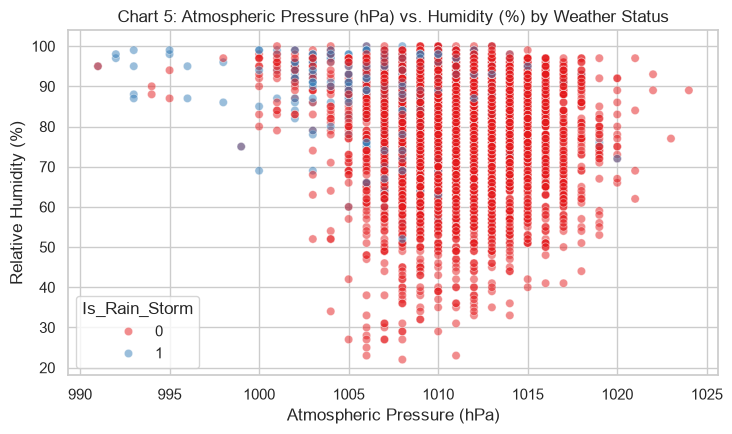

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# STAGE 1 & 2: PROBLEM DEFINITION, DATA LOADING & INSPECTION
df = pd.read_csv("calabarzon_weather.csv")
print("Initial CALABARZON Dataset Shape:", df.shape)
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# STAGE 3: REAL-WORLD DATA CLEANING & TARGET CREATION
dups = df.duplicated(subset=["city_name", "datetime"]).sum()
print(f"\nDuplicate rows found: {dups}")
df = df.drop_duplicates(subset=["city_name", "datetime"]).reset_index(drop=True)

cols_to_drop = [
    "sys.type", "sys.id", "weather.icon", "weather.id",
    "extraction_date_time", "coord.lon", "coord.lat",
    "sys.sunrise", "sys.sunset", "rain.1h"
]
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

for col in ["wind.gust", "main.sea_level", "main.grnd_level", "visibility"]:
    if col in df.columns and df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"Imputed '{col}' missing values with median: {median_val:.2f}")

df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Asia/Manila")
df["Is_Rain_Storm"] = df["weather.main"].apply(lambda w: 1 if w in ["Rain", "Thunderstorm"] else 0)

print("\nMissing Values After Cleaning:", df.isnull().sum().sum())
print("Cleaned Dataset Shape:", df.shape)
print("\nTarget Class Distribution (Is_Rain_Storm):")
print(df["Is_Rain_Storm"].value_counts())
print((df["Is_Rain_Storm"].value_counts(normalize=True) * 100).round(2))

# STAGE 4: EXPLORATORY DATA ANALYSIS (5 VISUALIZATIONS)
eda_df = df.copy()

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=eda_df, x="Is_Rain_Storm", palette="Set2", hue="Is_Rain_Storm", legend=False)
plt.title("Chart 1: Distribution of Weather Events (0 = No Rain, 1 = Rain/Storm)")
plt.xlabel("Weather Condition (0 = Clear/Cloudy, 1 = Rain/Thunderstorm)")
plt.ylabel("Number of Observations")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.savefig("fig0_class_dist.png", dpi=300)
plt.show()

top_cities = eda_df[eda_df["Is_Rain_Storm"] == 1]["city_name"].value_counts().head(10).index
plt.figure(figsize=(10, 4.5))
sns.countplot(data=eda_df[eda_df["city_name"].isin(top_cities)], x="city_name", hue="Is_Rain_Storm", palette="coolwarm")
plt.title("Chart 2: Rain/Storm vs. Non-Rain Observations Across Top 10 CALABARZON Cities")
plt.xlabel("CALABARZON City")
plt.ylabel("Observation Count")
plt.xticks(rotation=30)
plt.legend(title="Weather Status", labels=["No Rain (0)", "Rain/Storm (1)"])
plt.tight_layout()
plt.savefig("fig1_city_rain.png", dpi=300)
plt.show()

plt.figure(figsize=(9, 6.5))
num_cols = ["main.temp", "main.feels_like", "main.pressure", "main.humidity", "wind.speed", "wind.gust", "clouds.all", "visibility", "Is_Rain_Storm"]
sns.heatmap(eda_df[num_cols].corr(), annot=True, cmap="YlGnBu", fmt=".2f", linewidths=0.5)
plt.title("Chart 3: Correlation Matrix of CALABARZON Meteorological Features")
plt.tight_layout()
plt.savefig("fig2_correlation.png", dpi=300)
plt.show()

plt.figure(figsize=(6.5, 4))
sns.boxplot(data=eda_df, x="Is_Rain_Storm", y="main.humidity", palette="Blues", hue="Is_Rain_Storm", legend=False)
plt.title("Chart 4: Relative Humidity (%) vs. Rain/Storm Occurrence")
plt.xlabel("Weather Status (0 = No Rain, 1 = Rain/Storm)")
plt.ylabel("Relative Humidity (%)")
plt.tight_layout()
plt.savefig("fig0b_humidity_boxplot.png", dpi=300)
plt.show()

plt.figure(figsize=(7.5, 4.5))
sns.scatterplot(data=eda_df.sample(5000, random_state=42), x="main.pressure", y="main.humidity", hue="Is_Rain_Storm", alpha=0.5, palette="Set1")
plt.title("Chart 5: Atmospheric Pressure (hPa) vs. Humidity (%) by Weather Status")
plt.xlabel("Atmospheric Pressure (hPa)")
plt.ylabel("Relative Humidity (%)")
plt.legend(title="Is_Rain_Storm")
plt.tight_layout()
plt.savefig("fig3_pressure_humidity.png", dpi=300)
plt.show()


Training Set: (46655, 12) | Testing Set: (11664, 12)

--- Baseline Logistic Regression ---
Accuracy: 0.9124
Confusion Matrix:
 [[10462   114]
 [  908   180]]
              precision    recall  f1-score   support

           0       0.92      0.99      0.95     10576
           1       0.61      0.17      0.26      1088

    accuracy                           0.91     11664
   macro avg       0.77      0.58      0.61     11664
weighted avg       0.89      0.91      0.89     11664


--- Baseline Random Forest ---
Accuracy: 0.9237
Confusion Matrix:
 [[10491    85]
 [  805   283]]
              precision    recall  f1-score   support

           0       0.93      0.99      0.96     10576
           1       0.77      0.26      0.39      1088

    accuracy                           0.92     11664
   macro avg       0.85      0.63      0.67     11664
weighted avg       0.91      0.92      0.91     11664


--- Stage 8: Tuned Random Forest (GridSearchCV) ---
Best Parameters: {'classifier__class

,city_name,main.temp,main.feels_like,main.pressure,main.humidity,wind.speed,wind.gust,clouds.all,visibility,Month,Hour,Is_Wet_Season,Actual,Predicted
55090,Lucena,23.87,24.61,1009.0,88.0,4.78,8.28,98.0,10000.0,12,2,0,1,0
53752,Calamba,25.51,26.47,1010.0,90.0,5.65,10.88,100.0,10000.0,12,0,0,0,1
51966,Bacoor,25.98,25.98,1010.0,94.0,2.46,3.30,100.0,10000.0,12,20,0,1,0
37405,Cavite City,28.43,34.53,1007.0,87.0,1.54,4.47,100.0,8000.0,8,12,1,0,1
30563,Tayabas,23.50,24.49,1009.0,99.0,0.24,0.08,100.0,10000.0,7,21,1,0,1


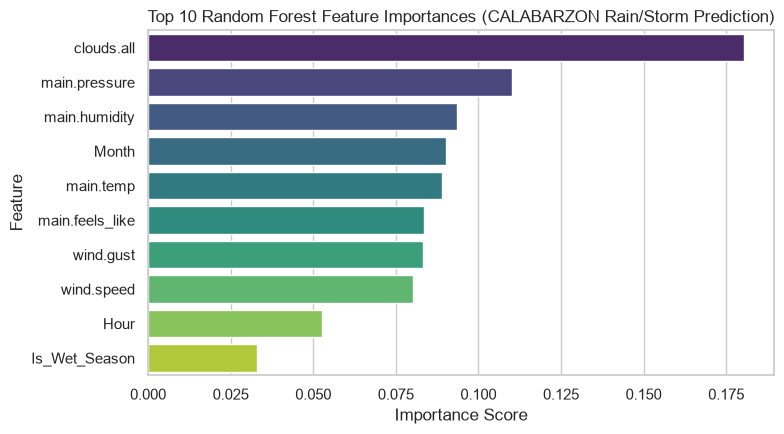

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# STAGE 5: FEATURE ENGINEERING & LEAK-FREE TRAIN-TEST SPLIT
df["Month"] = df["datetime"].dt.month
df["Hour"] = df["datetime"].dt.hour
df["Is_Wet_Season"] = df["Month"].apply(lambda m: 1 if 6 <= m <= 11 else 0)

categorical_features = ["city_name"]
numeric_features = [
    "main.temp", "main.feels_like", "main.pressure", "main.humidity",
    "wind.speed", "wind.gust", "clouds.all", "visibility", "Month", "Hour", "Is_Wet_Season"
]

X = df[categorical_features + numeric_features]
y = df["Is_Rain_Storm"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training Set: {X_train.shape} | Testing Set: {X_test.shape}")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features)
    ]
)

# STAGE 6 & 7: BASELINE MODEL TRAINING & EVALUATION
log_reg_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

log_reg_pipe.fit(X_train, y_train)
rf_pipe.fit(X_train, y_train)

for name, model in [("Baseline Logistic Regression", log_reg_pipe), ("Baseline Random Forest", rf_pipe)]:
    preds = model.predict(X_test)
    print(f"\n--- {name} ---")
    print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, preds))
    print(classification_report(y_test, preds))

# STAGE 8: HYPERPARAMETER TUNING (5-FOLD STRATIFIED CV + GRIDSEARCHCV)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grid = {
    "classifier__n_estimators": list((100, 200)),
    "classifier__max_depth": [15, None],
    "classifier__class_weight": [None, "balanced"]
}

grid_rf = GridSearchCV(rf_pipe, param_grid=param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid_rf.fit(X_train, y_train)

print("\n--- Stage 8: Tuned Random Forest (GridSearchCV) ---")
print("Best Parameters:", grid_rf.best_params_)
print(f"Best 5-Fold CV F1-Score: {grid_rf.best_score_:.4f}")

best_rf = grid_rf.best_estimator_
tuned_preds = best_rf.predict(X_test)
print("Tuned Test Accuracy:", round(accuracy_score(y_test, tuned_preds), 4))
print("Tuned Confusion Matrix:\n", confusion_matrix(y_test, tuned_preds))
print(classification_report(y_test, tuned_preds))

# ERROR ANALYSIS
err_mask = (tuned_preds != y_test)
misclassified = X_test[err_mask].copy()
misclassified["Actual"] = y_test[err_mask]
misclassified["Predicted"] = tuned_preds[err_mask]
print(f"\n--- Error Analysis: {len(misclassified)} Misclassified Test Rows (Sample 5) ---")
display(misclassified.head(5))

ohe_names = list(best_rf.named_steps["preprocessor"].named_transformers_["cat"].get_feature_names_out(categorical_features))
all_feat_names = numeric_features + ohe_names
importances = pd.Series(best_rf.named_steps["classifier"].feature_importances_, index=all_feat_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4.5))
sns.barplot(x=importances.values, y=importances.index, palette="viridis", hue=importances.index, legend=False)
plt.title("Top 10 Random Forest Feature Importances (CALABARZON Rain/Storm Prediction)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("fig4_feature_importance.png", dpi=300)
plt.show()


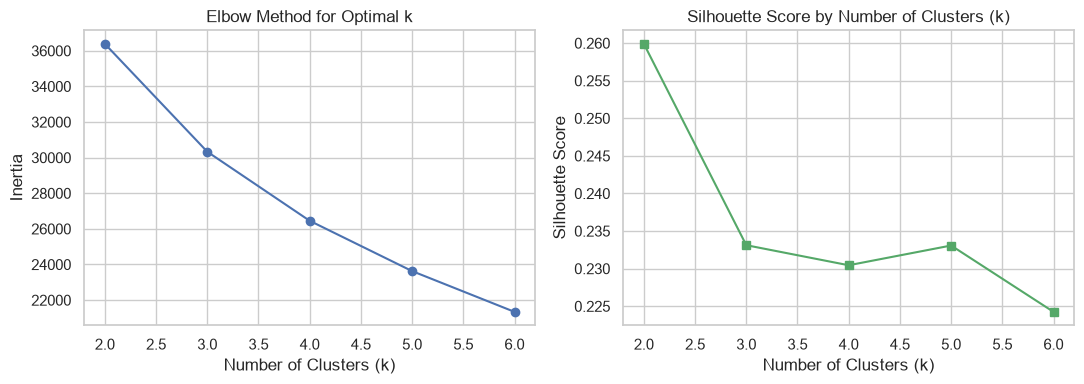


--- Stage 9: K-Means Cluster Profiles (Mean Values per Cluster) ---


,main.temp,main.pressure,main.humidity,wind.speed,clouds.all,Is_Rain_Storm
Weather_Cluster,,,,,,
0,25.98,1009.15,89.07,2.63,93.50,0.19
1,30.50,1010.30,65.78,4.16,59.52,0.04
2,25.41,1013.63,83.94,2.69,39.98,0.01


In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# STAGE 9: UNSUPERVISED EXTENSION - K-MEANS CLUSTERING
cluster_cols = ["main.temp", "main.pressure", "main.humidity", "wind.speed", "clouds.all"]
sample_cluster = df[cluster_cols + ["Is_Rain_Storm"]].sample(10000, random_state=42)
X_clust_scaled = StandardScaler().fit_transform(sample_cluster[cluster_cols])

inertias, sil_scores = [], []
k_range = range(2, 7)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_clust_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_clust_scaled, labels))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4))
ax0.plot(k_range, inertias, marker="o", color="b")
ax0.set_title("Elbow Method for Optimal k")
ax0.set_xlabel("Number of Clusters (k)")
ax0.set_ylabel("Inertia")

ax1.plot(k_range, sil_scores, marker="s", color="g")
ax1.set_title("Silhouette Score by Number of Clusters (k)")
ax1.set_xlabel("Number of Clusters (k)")
ax1.set_ylabel("Silhouette Score")
plt.tight_layout()
plt.savefig("fig5_kmeans.png", dpi=300)
plt.show()

final_km = KMeans(n_clusters=3, random_state=42, n_init=10)
sample_cluster["Weather_Cluster"] = final_km.fit_predict(X_clust_scaled)
print("\n--- Stage 9: K-Means Cluster Profiles (Mean Values per Cluster) ---")
display(sample_cluster.groupby("Weather_Cluster")[cluster_cols + ["Is_Rain_Storm"]].mean().round(2))


## Stage 10: Deployment, Monitoring, Maintenance, and Ethics

### 1. Deployment Plan
The finalized Random Forest pipeline (`best_rf`) can be serialized using `joblib` (`joblib.dump(best_rf, "calabarzon_rain_model.pkl")`) and exposed behind a lightweight FastAPI REST endpoint. Every three hours, automated weather telemetry feeds across the 18 monitored CALABARZON cities (`city_name`, `main.temp`, `main.feels_like`, `main.pressure`, `main.humidity`, `wind.speed`, `wind.gust`, `clouds.all`, `visibility`, and extracted time indicators) can be submitted to generate real-time rain/storm alerts and K-Means readiness tiers for local DRRM command centers.

### 2. Monitoring, Data Drift, and Retraining Plan
* **Performance Monitoring:** Log model predictions against verified post-storm PAGASA and local DRRMO weather incident reports to track rolling Precision, Recall, and F1-score.
* **Data Drift Detection:** Monitor incoming sensor distributions (such as shifting seasonal pressure or temperature baselines during El Niño/La Niña cycles) for statistical drift.
* **Retraining Schedule:** Re-run the full 10-stage preprocessing and training pipeline annually every December after the Philippine wet season ends, or trigger immediate retraining if rain/storm Recall drops below `0.45`.

### 3. Ethical Considerations & Bias Mitigation
* **Regional Sampling Bias:** Training data covers 18 urbanized CALABARZON cities; rural upland or coastal municipalities without automated weather stations may exhibit distinct microclimates.
* **Safety Trade-Off in False Negatives:** Missing an incoming storm poses higher community safety risk than issuing a precautionary rain watch, justifying `class_weight="balanced"` to prioritize minority-class Recall.
* **Human-in-the-Loop Governance:** Automated alerts must supplement—never replace—official PAGASA advisories and local DRRM officer judgment.
* **Data Privacy:** All records contain aggregated atmospheric telemetry with zero personally identifiable information (PII), posing no privacy risks.
